# Case Study 07 — What Drives the Loan Amount a Customer Requests?

**Multiple regression · individual vs conditional relationships · "holding other variables constant" · omitted-variable
bias · dummy variables and reference categories · categorical × numeric interactions · nested F-tests · standardised
coefficients · % effects in log models · variables that must NOT be in the model**

| | |
|---|---|
| **Domain** | Retail lending: offer design and disbursement forecasting |
| **Stakeholders** | Head of Personal Loans (Product), Finance (planning) |
| **Difficulty** | Intermediate |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 05 (correlation, confounding), Case 06 (simple regression, log models) |
| **Data** | 5,000 personal-loan applications (requested amounts, before credit decisions) |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. The difference between **"Y vs X"** (individual relationship) and **"Y vs X given everything else"** (conditional
   relationship), and why coefficients **change, vanish or flip sign** when variables are added.
2. How to interpret multiple-regression coefficients correctly, including **dummy variables** and **interactions**.
3. How to test whether a **group of variables** matters (nested F-test), and how to talk about **variable importance**
   carefully.
4. Why some variables must be **left out** of a driver model even though they improve R².

## Section 1 — Business context

You are a data scientist working with the **Personal Loans** product team and **Finance**. In Case 06 we built a
branch rule from income alone. It worked, but its ranges were wide: income explained only about 55–60% of the
variation.

The Head of Personal Loans writes:

> *"Before we redesign our tiered offers, I want to understand what really drives how much customers ask for. My
> team has a list of beliefs from the dashboards: metro customers ask for more; older customers ask for more;
> customers with more existing EMIs ask for more, because they're 'credit-hungry'; better credit scores mean bigger
> requests. Which of these are real? And can we build a better estimate of the requested amount for Finance's
> disbursement forecast?"*

The data: **5,000 recent applications**, with the **requested** amount (customer demand, before any credit decision).

## Section 2 — Business questions

1. Which customer characteristics are associated with the requested amount **once the others are taken into
   account**?
2. Are the dashboard beliefs (city tier, age, existing EMIs, credit score) real drivers or side-effects of income?
3. Does the effect of income differ between salaried and self-employed customers?
4. How much does the loan purpose matter?
5. How well can we predict the requested amount, and with what uncertainty?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | What matters, all else equal? | Conditional (partial) coefficients in a multiple regression | OLS on log(amount) with all candidate drivers |
| 2 | Are the beliefs real? | Does each variable's **simple** coefficient survive **adjustment**? | Simple vs multiple coefficients; nested F-tests |
| 3 | Different income effect by job type? | Is there an income × employment **interaction**? | Interaction term + F-test |
| 4 | How much does purpose matter? | Size and significance of the purpose **dummies** as a group | F-test for the block; % effects |
| 5 | How well can we predict? | Out-of-sample error and prediction intervals | Holdout R², PI coverage |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "07_loan_amount_drivers"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(707)
kfmt = thousands_formatter("₹", "k", 1e3, 0)
lfmt = thousands_formatter("₹", "L", 1e5, 1)

def pct(b):
    # Coefficient on the log scale -> % change in the requested amount.
    return 100 * (np.exp(b) - 1)

## Section 4 — Load the data

In [2]:
apps = pd.read_csv(PATHS["data"] / "loan_applications.csv")
print(f"{apps.shape[0]:,} applications × {apps.shape[1]} columns;  duplicates: {apps['application_id'].duplicated().sum()};  "
      f"missing: {apps.isna().sum().sum()}")
display(apps.head())
pd.DataFrame({"type": ["numeric (₹)", "numeric (₹)", "numeric", "numeric", "nominal (3)", "nominal (6)", "ordinal (4)",
                       "discrete (choice)", "numeric (₹) TARGET"],
              "role": ["driver", "driver", "driver", "driver", "driver", "driver", "driver",
                       "chosen WITH the amount, not a driver (Section 11)", "outcome"]},
             index=apps.columns[1:])

5,000 applications × 10 columns;  duplicates: 0;  missing: 0


,application_id,monthly_income,existing_emi,age,credit_score,employment_type,loan_purpose,city_tier,requested_tenure_months,requested_amount
0,APP7100000,"41,000.0000","8,700.0000",37,710,Salaried,Home renovation,Tier-1,24,90000
1,APP7100001,"60,800.0000","1,800.0000",50,728,Salaried,Wedding,Tier-1,48,260000
2,APP7100002,"93,500.0000","2,300.0000",30,713,Salaried,Education,Metro,48,270000
3,APP7100003,"29,900.0000","4,400.0000",37,654,Salaried,Medical,Metro,12,50000
4,APP7100004,"69,900.0000","18,900.0000",30,641,Salaried,Home renovation,Tier-3,12,150000


,type,role
monthly_income,numeric (₹),driver
existing_emi,numeric (₹),driver
age,numeric,driver
credit_score,numeric,driver
employment_type,nominal (3),driver
loan_purpose,nominal (6),driver
city_tier,ordinal (4),driver
requested_tenure_months,discrete (choice),"chosen WITH the amount, not a driver (Section 11)"
requested_amount,numeric (₹) TARGET,outcome


The data is clean (no missing values, no duplicates, all values within business ranges). We go straight to the
analysis and hold back a **20% sample** for honest prediction checks.

In [3]:
apps["log_amount"] = np.log(apps["requested_amount"])
apps["log_income"] = np.log(apps["monthly_income"] / 50_000)   # log income CENTRED at ₹50,000 (see note below)
apps["existing_emi_k"] = apps["existing_emi"] / 1000          # coefficients per ₹1,000 of existing EMI
apps["emi_share"] = apps["existing_emi"] / apps["monthly_income"]
for c, ref in [("employment_type", "Salaried"), ("loan_purpose", "Debt consolidation"), ("city_tier", "Metro")]:
    levels = [ref] + sorted(l for l in apps[c].unique() if l != ref)
    apps[c] = pd.Categorical(apps[c], categories=levels)
test_idx = rng.choice(apps.index, size=int(0.2 * len(apps)), replace=False)
test, train = apps.loc[test_idx].copy(), apps.drop(index=test_idx).copy()
print(f"train {len(train):,} / holdout {len(test):,}")

train 4,000 / holdout 1,000


**Centring.** We use log(income ÷ ₹50,000) rather than log(income). The slope (elasticity) is identical, but the
intercept and the group dummies now describe a customer earning **₹50,000**, a realistic customer rather than one
earning ₹1. This matters most once interactions are added (Section 10).

**Reference categories.** For each categorical variable we choose the **reference** (baseline) level on purpose: the
largest or most natural comparison group (Salaried, Debt consolidation, Metro). Each dummy coefficient is then "this
level **compared with the reference**". The choice changes the coefficients' wording, not the model's predictions.

## Section 5 — Descriptive statistics

In [4]:
num = ["requested_amount", "monthly_income", "existing_emi", "emi_share", "age", "credit_score"]
display(train[num].describe(percentiles=[0.05, 0.5, 0.95]).T[["mean", "50%", "std", "5%", "95%"]])
cat_summary = pd.concat({c: train.groupby(c, observed=True).agg(n=("requested_amount", "size"),
                                                               median_amount=("requested_amount", "median"),
                                                               median_income=("monthly_income", "median"))
                         for c in ["employment_type", "loan_purpose", "city_tier"]})
save_table(cat_summary, "category_summary", PATHS["tables"])
cat_summary

,mean,50%,std,5%,95%
requested_amount,"126,515.0000","100,000.0000","99,314.0000","50,000.0000","300,000.0000"
monthly_income,"64,132.9750","56,500.0000","34,906.0311","24,400.0000","131,905.0000"
existing_emi,"11,891.1750","8,200.0000","12,977.1049",0.0000,"36,000.0000"
emi_share,0.1832,0.1662,0.1492,0.0000,0.4702
age,36.2797,36.0000,8.6960,22.0000,51.0000
credit_score,715.5163,715.0000,52.1558,631.0000,801.0000


n  median_amount  median_income
employment_type Salaried            2521    90,000.0000    53,300.0000
                Professional         359   140,000.0000    74,200.0000
                Self-employed       1120   110,000.0000    58,100.0000
loan_purpose    Debt consolidation  1194    90,000.0000    56,200.0000
                Education            372   110,000.0000    57,150.0000
                Home renovation      750   130,000.0000    56,300.0000
                Medical              475    80,000.0000    55,900.0000
                Travel               741    60,000.0000    56,400.0000
                Wedding              468   140,000.0000    57,450.0000
city_tier       Metro               1339   120,000.0000    67,800.0000
                Tier-1              1068   100,000.0000    56,300.0000
                Tier-2              1013    80,000.0000    51,300.0000
                Tier-3               580    70,000.0000    44,250.0000

Already visible: **metro customers request more, but they also earn more**. Professionals earn the most. Wedding and
home-renovation loans are the largest requests. Every one of these group differences mixes the group's own effect with
income differences. Multiple regression separates them.

## Section 6 — Visualisation: the individual relationships

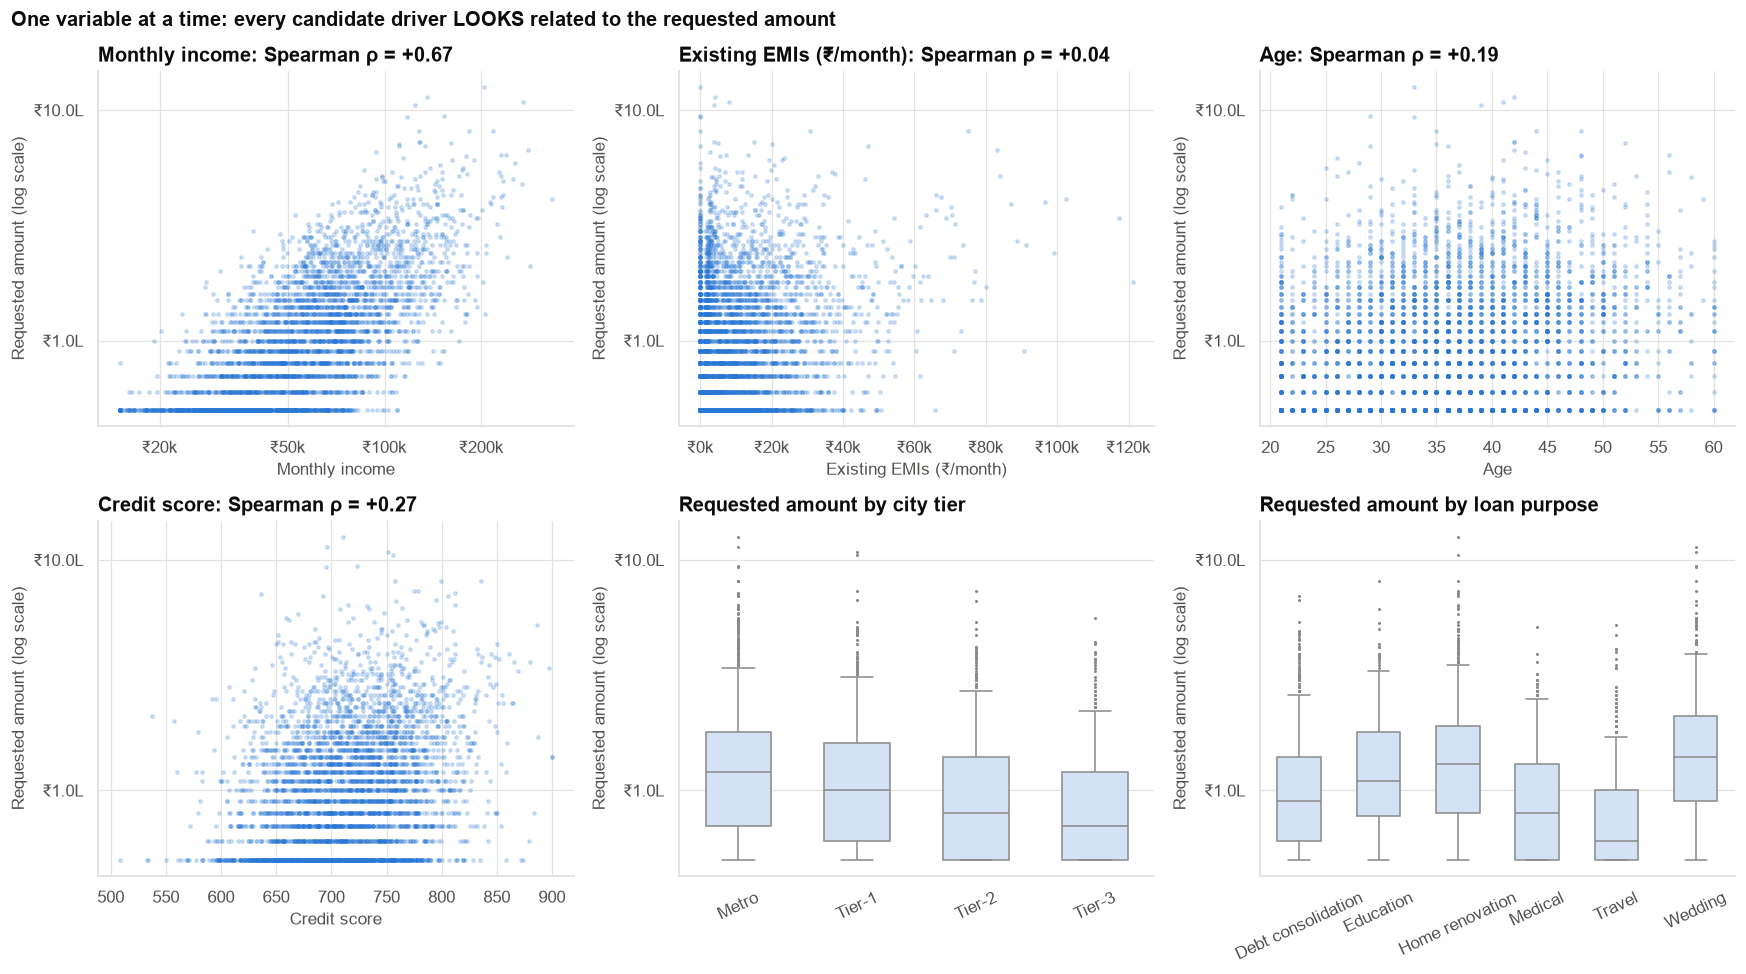

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (col, label, fmtr) in zip(axes[0], [("monthly_income", "Monthly income", kfmt), ("existing_emi", "Existing EMIs (₹/month)", kfmt),
                                            ("age", "Age", None)]):
    ax.scatter(train[col], train["requested_amount"], s=5, alpha=0.2, color=PRIMARY)
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(lfmt)
    if col == "monthly_income":
        ax.set_xscale("log")
        ax.set_xticks([20_000, 50_000, 100_000, 200_000])
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
    if fmtr:
        ax.xaxis.set_major_formatter(fmtr)
    r = stats.spearmanr(train[col], train["requested_amount"])[0]
    ax.set(title=f"{label}: Spearman ρ = {r:+.2f}", xlabel=label, ylabel="Requested amount (log scale)")
ax = axes[1, 0]
ax.scatter(train["credit_score"], train["requested_amount"], s=5, alpha=0.2, color=PRIMARY)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(lfmt)
ax.set(title=f"Credit score: Spearman ρ = {stats.spearmanr(train['credit_score'], train['requested_amount'])[0]:+.2f}",
       xlabel="Credit score", ylabel="Requested amount (log scale)")
for ax, col in zip(axes[1, 1:], ["city_tier", "loan_purpose"]):
    order = list(train[col].cat.categories)
    sns.boxplot(data=train, x=col, y="requested_amount", order=order, ax=ax, color="#cde2fb", fliersize=1, width=0.55)
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(lfmt)
    ax.set(title=f"Requested amount by {col.replace('_', ' ')}", xlabel="", ylabel="Requested amount (log scale)")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("One variable at a time: every candidate driver LOOKS related to the requested amount",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig01_individual_relationships", PATHS["figures"])
plt.show()

**Observation.** Taken one at a time, income, existing EMIs, age, credit score, city tier and purpose all appear
related to the requested amount.

**Interpretation.** Each of these plots shows a **marginal** (individual) relationship. It mixes the variable's own
association with everything that travels with it. Higher earners carry bigger EMIs, are older on average, live in
metros and have better scores. So each of those variables partly **stands in for income**.

**Caveat.** We cannot tell from these plots which variables matter **in their own right**. That is the job of multiple
regression.

## Section 7 — Method selection

```text
Outcome     : requested amount, continuous, right-skewed, multiplicative noise (Case 06) → model log(amount)
Predictors  : numeric (income, existing EMI, age, score), nominal (employment, purpose), ordinal (city tier)
Goal        : (a) explanation: which drivers matter, all else equal  (b) prediction for Finance
```

| Candidate | Verdict |
|---|---|
| Separate simple regressions / correlations | ❌ Mixes each variable's effect with those of correlated variables |
| **Multiple linear regression on log(amount)** | ✅ Estimates each variable's association **holding the others constant**; log scale gives % interpretations and stable variance |
| Tree-based ML | ❌ Not needed for explanation here, and less interpretable (see the Case 13 playbook) |

**The model**

  log(amount) = β₀ + β₁·log(income) + β₂·existing EMI + β₃·age + β₄·score + Σ γ·[employment dummies] +
  Σ δ·[purpose dummies] + Σ θ·[city-tier dummies] + ε

**How to read a coefficient (log outcome):** a one-unit increase in X, *holding all other variables in the model
fixed*, multiplies the expected requested amount by e^β, i.e. changes it by **(e^β − 1) × 100%**. For log(income) the
coefficient is an **elasticity**.

> **"Holding other variables constant" is a statement about the model, not about the world.** It means comparing
> customers who are alike on the other variables **in the model**. It is only as good as the variables we include.

## Section 8 — Building the model step by step

### 8.1 Simple (individual) regressions, one variable at a time

In [6]:
simple_specs = {"log_income": "log_income", "existing_emi_k": "existing_emi_k", "age": "age", "credit_score": "credit_score"}
simple = {}
for name, f in simple_specs.items():
    m = smf.ols(f"log_amount ~ {f}", train).fit()
    simple[name] = {"coef": m.params[name], "ci_low": m.conf_int().loc[name, 0], "ci_high": m.conf_int().loc[name, 1],
                    "p_value": m.pvalues[name], "R²": m.rsquared}
m_tier = smf.ols("log_amount ~ city_tier", train).fit()
for lvl in ["Tier-1", "Tier-2", "Tier-3"]:
    k = f"city_tier[T.{lvl}]"
    simple[f"city_tier: {lvl} vs Metro"] = {"coef": m_tier.params[k], "ci_low": m_tier.conf_int().loc[k, 0],
                                            "ci_high": m_tier.conf_int().loc[k, 1], "p_value": m_tier.pvalues[k], "R²": m_tier.rsquared}
simple = pd.DataFrame(simple).T
simple

,coef,ci_low,ci_high,p_value,R²
log_income,0.8081,0.7806,0.8356,0.0000,0.4542
existing_emi_k,0.0060,0.0045,0.0074,0.0000,0.0163
age,0.0131,0.0110,0.0152,0.0000,0.0352
credit_score,0.0032,0.0028,0.0035,0.0000,0.0746
city_tier: Tier-1 vs Metro,-0.1405,-0.1882,-0.0929,0.0000,0.0477
city_tier: Tier-2 vs Metro,-0.2594,-0.3078,-0.2110,0.0000,0.0477
city_tier: Tier-3 vs Metro,-0.3702,-0.4279,-0.3124,0.0000,0.0477


### 8.2 Adding variables in steps: watch the coefficients move

In [7]:
steps = {
    "M1: income only": "log_amount ~ log_income",
    "M2: + existing EMI": "log_amount ~ log_income + existing_emi_k",
    "M3: + employment, purpose": "log_amount ~ log_income + existing_emi_k + employment_type + loan_purpose",
    "M4: + age, score, city tier (full)": "log_amount ~ log_income + existing_emi_k + employment_type + loan_purpose + age + credit_score + city_tier",
    "M5: + income × employment": "log_amount ~ log_income * employment_type + existing_emi_k + loan_purpose + age + credit_score + city_tier",
}
models = {k: smf.ols(f, train).fit() for k, f in steps.items()}
track = ["log_income", "existing_emi_k", "age", "credit_score", "city_tier[T.Tier-3]", "employment_type[T.Professional]"]
coef_path = pd.DataFrame({k: m.params.reindex(track) for k, m in models.items()}).T
coef_path["R²"] = [m.rsquared for m in models.values()]
coef_path["adj. R²"] = [m.rsquared_adj for m in models.values()]
coef_path["params"] = [int(m.df_model) for m in models.values()]
save_table(coef_path, "coefficient_path", PATHS["tables"])
coef_path

,log_income,existing_emi_k,age,credit_score,city_tier[T.Tier-3],employment_type[T.Professional],R²,adj. R²,params
M1: income only,0.8081,NaN,NaN,NaN,NaN,NaN,0.4542,0.4541,1
M2: + existing EMI,0.9667,-0.0126,NaN,NaN,NaN,NaN,0.5090,0.5087,2
"M3: + employment, purpose",0.9536,-0.0124,NaN,NaN,NaN,0.1420,0.6487,0.6479,9
"M4: + age, score, city tier (full)",0.9249,-0.0123,-0.0007,0.0010,-0.0025,0.1333,0.6552,0.6540,14
M5: + income × employment,0.8670,-0.0124,-0.0007,0.0010,-0.0013,0.0984,0.6591,0.6578,16


**Read the table column by column. This is the heart of the case.**

- **Income:** elasticity ≈ 0.81 alone, rising to ≈ 0.97 once existing EMIs are in the model (≈ 0.92 in the full model). Leaving out a variable that
  is *correlated with income* and *affects the outcome* biased the income coefficient: **omitted-variable bias**.
- **Existing EMI:** its effect **flips sign** once income is controlled (shown next).
- **Age, credit score, city tier:** they are not in the early models. When they enter (M4), their coefficients are far
  smaller than in their simple regressions (8.1). They were mostly carrying income's effect.
- **R²** rises from about 0.45 to about 0.66. **Adjusted R²** (which penalises extra parameters) rises almost as much, so
  the additions are genuinely informative.

### 8.3 The existing-EMI sign flip

Existing EMI, simple regression : +0.60% per extra ₹1,000 of existing EMI
Existing EMI, full model         : -1.22% per extra ₹1,000 (holding income etc. fixed)
Correlation of existing EMI with income: 0.53


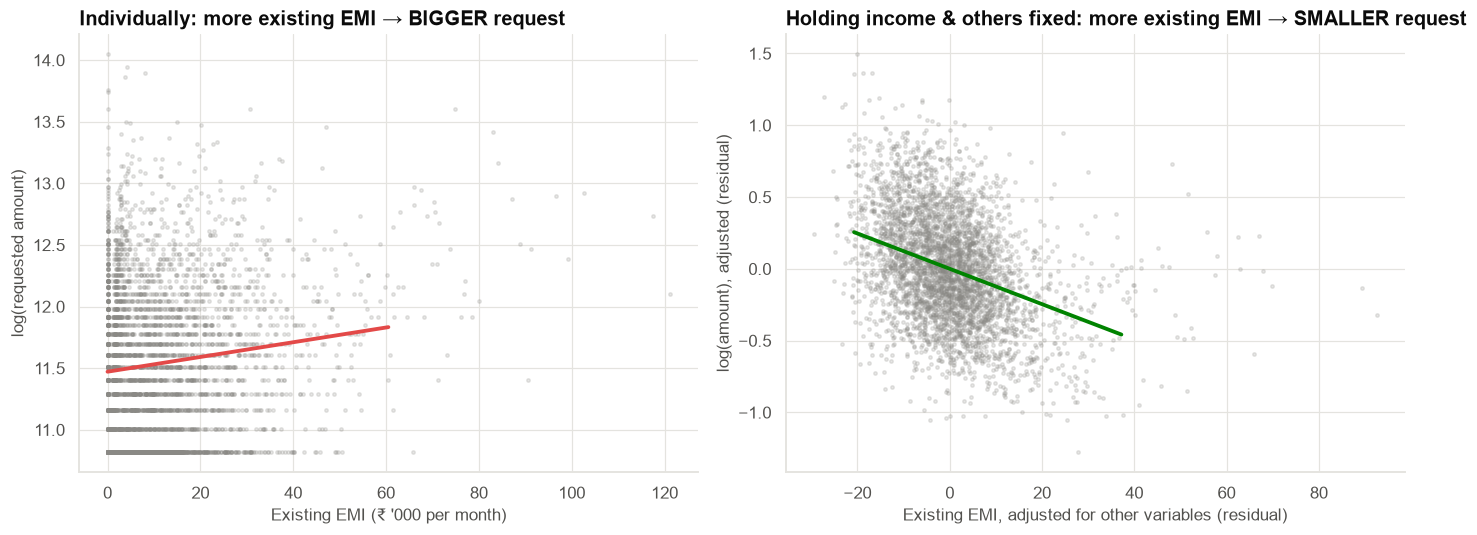

In [8]:
m_full = models["M4: + age, score, city tier (full)"]
b_simple, b_full = simple.loc["existing_emi_k", "coef"], m_full.params["existing_emi_k"]
print(f"Existing EMI, simple regression : {pct(b_simple):+.2f}% per extra ₹1,000 of existing EMI")
print(f"Existing EMI, full model         : {pct(b_full):+.2f}% per extra ₹1,000 (holding income etc. fixed)")
print(f"Correlation of existing EMI with income: {np.corrcoef(train['existing_emi'], train['monthly_income'])[0, 1]:.2f}")

# Added-variable (partial regression) plot: residualise both Y and existing EMI on the other predictors.
others = "log_income + employment_type + loan_purpose + age + credit_score + city_tier"
ry = smf.ols(f"log_amount ~ {others}", train).fit().resid
rx = smf.ols(f"existing_emi_k ~ {others}", train).fit().resid
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(train["existing_emi_k"], train["log_amount"], s=5, alpha=0.2, color=INK_MUTED)
b = np.polyfit(train["existing_emi_k"], train["log_amount"], 1)
xs = np.linspace(0, train["existing_emi_k"].quantile(0.99), 50)
ax.plot(xs, np.polyval(b, xs), color=COLORS["red"], lw=2.5)
ax.set(title="Individually: more existing EMI → BIGGER request", xlabel="Existing EMI (₹ '000 per month)", ylabel="log(requested amount)")
ax = axes[1]
ax.scatter(rx, ry, s=5, alpha=0.2, color=INK_MUTED)
b2 = np.polyfit(rx, ry, 1)
xs2 = np.linspace(rx.quantile(0.01), rx.quantile(0.99), 50)
ax.plot(xs2, np.polyval(b2, xs2), color=COLORS["green"], lw=2.5)
ax.set(title="Holding income & others fixed: more existing EMI → SMALLER request",
       xlabel="Existing EMI, adjusted for other variables (residual)", ylabel="log(amount), adjusted (residual)")
fig.tight_layout()
save_fig(fig, "fig02_emi_sign_flip", PATHS["figures"])
plt.show()

**Observation.** Individually, customers with more existing EMIs ask for slightly **more**. Among customers with the
same income (and the same other characteristics), those with more existing EMIs ask for **less**, about 1.2% less per
extra ₹1,000 of monthly EMI.

**Interpretation.** Higher earners carry bigger EMIs in rupee terms (correlation ≈ 0.5) and also request bigger loans.
That creates a positive *marginal* association. Holding income fixed, an extra EMI eats into affordability, so the
request is smaller. The right-hand panel is an **added-variable plot**: it shows the relationship the multiple
regression actually estimates, after removing what the other variables explain from both axes.

**Business implication.** The "credit-hungry" belief is backwards. **For a given income, indebted customers ask for
less.** That is what affordability-based offers should reflect.

**Caveat.** Conditional on the variables *in the model*. An omitted variable related to both EMIs and demand could still
change this picture.

### 8.4 Individual vs conditional, side by side

In [9]:
compare = pd.DataFrame({
    "individual (simple) coef": [simple.loc["log_income", "coef"], simple.loc["existing_emi_k", "coef"], simple.loc["age", "coef"],
                                 simple.loc["credit_score", "coef"], simple.loc["city_tier: Tier-3 vs Metro", "coef"]],
    "conditional (full model) coef": [m_full.params["log_income"], m_full.params["existing_emi_k"], m_full.params["age"],
                                      m_full.params["credit_score"], m_full.params["city_tier[T.Tier-3]"]],
    "conditional p-value": [m_full.pvalues["log_income"], m_full.pvalues["existing_emi_k"], m_full.pvalues["age"],
                            m_full.pvalues["credit_score"], m_full.pvalues["city_tier[T.Tier-3]"]],
}, index=["log income (elasticity)", "existing EMI (per ₹1k)", "age (per year)", "credit score (per point)", "Tier-3 vs Metro"])
compare["individual % effect"] = compare["individual (simple) coef"].map(pct)
compare["conditional % effect"] = compare["conditional (full model) coef"].map(pct)
compare.loc["log income (elasticity)", ["individual % effect", "conditional % effect"]] = np.nan
compare["what happened"] = ["grew (omitted-variable bias removed)", "flipped sign", "vanished (proxy for income)",
                            "shrank by ~2/3", "vanished (proxy for income)"]
save_table(compare, "individual_vs_conditional", PATHS["tables"])
compare

,individual (simple) coef,conditional (full model) coef,conditional p-value,individual % effect,conditional % effect,what happened
log income (elasticity),0.8081,0.9249,0.0000,NaN,NaN,grew (omitted-variable bias removed)
existing EMI (per ₹1k),0.0060,-0.0123,0.0000,0.5995,-1.2232,flipped sign
age (per year),0.0131,-0.0007,0.3114,1.3190,-0.0704,vanished (proxy for income)
credit score (per point),0.0032,0.0010,0.0000,0.3184,0.0965,shrank by ~2/3
Tier-3 vs Metro,-0.3702,-0.0025,0.8950,-30.9377,-0.2466,vanished (proxy for income)


**Why coefficients change when variables are added.**

| Pattern | Mechanism | Example here |
|---|---|---|
| Coefficient **shrinks or vanishes** | X was a **proxy**: it is correlated with a real driver that was left out (confounding) | Age, city tier (proxies for income) |
| Coefficient **grows** | A left-out variable was pulling the other way (**omitted-variable bias** towards zero) | Income, once existing EMIs are included |
| Coefficient **flips sign** | Marginal and conditional associations have opposite directions | Existing EMI |
| Coefficient **stable** | X is nearly uncorrelated with the added variables | Purpose effects |

Case 08 studies confounding and suppression in depth. Case 09 covers what happens when predictors are so correlated
that coefficients become unstable.

## Section 9 — Testing groups of variables (nested F-tests)

Is **city tier** worth keeping? It has three dummies, so we test them **together**: does the full model fit
significantly better than the model without city tier?

In [10]:
def nested_f(small_formula, big_formula, data=train):
    small, big = smf.ols(small_formula, data).fit(), smf.ols(big_formula, data).fit()
    a = anova_lm(small, big)
    return {"F": a["F"].iloc[1], "df": int(a["df_diff"].iloc[1]), "p_value": a["Pr(>F)"].iloc[1],
            "partial R²": (small.ssr - big.ssr) / small.ssr}

full_f = steps["M4: + age, score, city tier (full)"]
blocks = {
    "city tier (3 dummies)": full_f.replace(" + city_tier", ""),
    "loan purpose (5 dummies)": full_f.replace(" + loan_purpose", ""),
    "employment type (2 dummies)": full_f.replace(" + employment_type", ""),
    "age": full_f.replace(" + age", ""),
    "credit score": full_f.replace(" + credit_score", ""),
    "existing EMI": full_f.replace(" + existing_emi_k", ""),
    "log income": full_f.replace("log_income + ", ""),
}
ftests = pd.DataFrame({name: nested_f(small, full_f) for name, small in blocks.items()}).T.sort_values("partial R²", ascending=False)
f_int = nested_f(full_f, steps["M5: + income × employment"])
ftests.loc["income × employment interaction (2 terms)"] = f_int
ftests["p_value"] = ftests["p_value"].astype(float)
save_table(ftests, "nested_f_tests", PATHS["tables"])
ftests

,F,df,p_value,partial R²
log income,"4,068.1196",1.0000,0.0000,0.5052
loan purpose (5 dummies),307.9586,5.0000,0.0000,0.2787
existing EMI,601.7518,1.0000,0.0000,0.1312
employment type (2 dummies),43.1156,2.0000,0.0000,0.0212
credit score,72.0866,1.0000,0.0000,0.0178
city tier (3 dummies),1.1183,3.0000,0.3402,0.0008
age,1.0251,1.0000,0.3114,0.0003
income × employment interaction (2 terms),22.8968,2.0000,0.0000,0.0114


**Reading the F-tests.** Each row asks: "does this variable (or block) add explanatory power **beyond everything
else**?" The **partial R²** is the share of the *remaining* unexplained variance that the block accounts for. It is an
honest measure of each block's unique contribution.

- **Income** is by far the dominant driver, followed by **loan purpose** and **existing EMIs**.
- **City tier** and **age** add nothing once income is in the model (p ≫ 0.05, partial R² ≈ 0). They are proxies.
- **Credit score** adds a small but real amount.
- The **income × employment interaction** is significant: next section.

> **"Importance" in regression has no single definition.** Partial R² from drop-one F-tests measures unique
> contribution. Standardised coefficients measure the effect of a one-SD change (below). Neither says what would happen
> if we *changed* a variable. For that you need a causal design (Case 21).

## Section 10 — Interaction: does income matter more for the self-employed?

,income elasticity,ci_low,ci_high
employment,,,
Salaried,0.8670,0.8340,0.8999
Self-employed,1.0310,0.9851,1.0769
Professional,1.0055,0.9330,1.0779


Interaction F-test: F = 22.9, df = 2, p = < 0.001


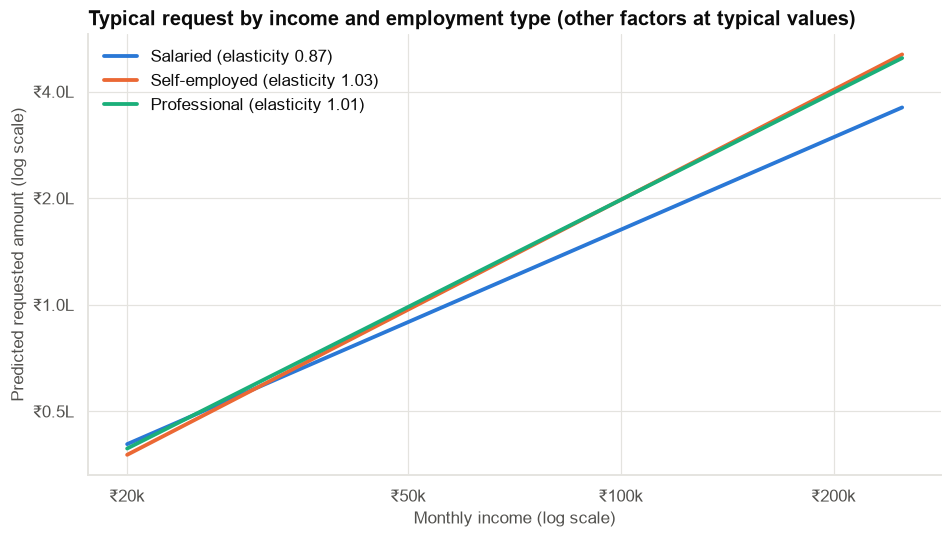

In [11]:
m_int = models["M5: + income × employment"]
slopes = {"Salaried": m_int.params["log_income"]}
for g in ["Self-employed", "Professional"]:
    slopes[g] = m_int.params["log_income"] + m_int.params[f"log_income:employment_type[T.{g}]"]
cov = m_int.cov_params()
slope_tbl = []
for g, s in slopes.items():
    if g == "Salaried":
        se = np.sqrt(cov.loc["log_income", "log_income"])
    else:
        k = f"log_income:employment_type[T.{g}]"
        se = np.sqrt(cov.loc["log_income", "log_income"] + cov.loc[k, k] + 2 * cov.loc["log_income", k])
    slope_tbl.append({"employment": g, "income elasticity": s, "ci_low": s - 1.96 * se, "ci_high": s + 1.96 * se})
slope_tbl = pd.DataFrame(slope_tbl).set_index("employment")
save_table(slope_tbl, "income_elasticity_by_employment", PATHS["tables"])
display(slope_tbl)
print(f"Interaction F-test: F = {f_int['F']:.1f}, df = {f_int['df']}, p = {fmt_p(f_int['p_value'])}")

fig, ax = plt.subplots(figsize=(10, 5.2))
inc_grid = np.linspace(np.log(20_000), np.log(250_000), 50)   # raw log income for the x-axis
base = {"existing_emi_k": train["existing_emi_k"].median(), "loan_purpose": "Debt consolidation", "age": 36,
        "credit_score": 720, "city_tier": "Metro"}
for g, color in [("Salaried", COLORS["blue"]), ("Self-employed", COLORS["orange"]), ("Professional", COLORS["aqua"])]:
    grid = pd.DataFrame({"log_income": inc_grid - np.log(50_000), "employment_type": g, **base})
    for c in ["employment_type", "loan_purpose", "city_tier"]:
        grid[c] = pd.Categorical(grid[c], categories=train[c].cat.categories)
    ax.plot(np.exp(inc_grid), np.exp(m_int.predict(grid)), lw=2.5, color=color, label=f"{g} (elasticity {slopes[g]:.2f})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([20_000, 50_000, 100_000, 200_000]); ax.set_yticks([50_000, 100_000, 200_000, 400_000])
ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.xaxis.set_major_formatter(kfmt); ax.yaxis.set_major_formatter(lfmt)
ax.set(title="Typical request by income and employment type (other factors at typical values)",
       xlabel="Monthly income (log scale)", ylabel="Predicted requested amount (log scale)")
ax.legend(loc="upper left")
save_fig(fig, "fig03_interaction_income_employment", PATHS["figures"])
plt.show()

**An interaction means the effect of one variable depends on another.** Here the income elasticity is steeper for
**self-employed** customers: a 10% higher income goes with a larger % increase in their request than for salaried
customers. Without the interaction, the model forces one common slope and mis-predicts high- and low-income
self-employed customers in opposite directions.

**Interpreting main effects when an interaction is present.** With an interaction, the "employment_type" dummies are
the group differences **at the point where the centred income is zero**, i.e. at ₹50,000 a month. Without centring they
would be differences at an income of ₹1 (huge, meaningless numbers). Always centre, or compare groups at realistic
incomes as the plot does.

## Section 11 — A variable that must stay out: requested tenure

In [12]:
m_tenure = smf.ols(full_f + " + requested_tenure_months", train).fit()
print(f"R² without tenure: {m_full.rsquared:.3f}   with tenure: {m_tenure.rsquared:.3f}")
print(f"Income elasticity without tenure: {m_full.params['log_income']:.3f}   with tenure: {m_tenure.params['log_income']:.3f}")
print(f"Tenure coefficient: {pct(m_tenure.params['requested_tenure_months']):+.2f}% per extra month of tenure")

R² without tenure: 0.655   with tenure: 0.718
Income elasticity without tenure: 0.925   with tenure: 0.748
Tenure coefficient: +1.43% per extra month of tenure


Adding requested tenure raises R² noticeably and **shrinks the income effect**. It is still the wrong thing to do:

1. **It is decided together with the amount.** Customers who want bigger loans choose longer tenures to keep the EMI
   affordable. Tenure is part of the *outcome*, not a cause of it. Including it "explains" the amount with a piece of
   the amount itself.
2. **It steals credit from real drivers.** Part of income's effect works *through* the tenure choice (richer customers
   want bigger loans and therefore longer tenures). Controlling for tenure removes that part, so the income
   coefficient no longer answers the business question.
3. **It is not available when we need the prediction** (pre-application offers and early forecasts).

> **Rule:** in a driver (explanatory) model, include variables that are determined **before** the outcome. Exclude
> variables that are **consequences** of it or chosen with it ("bad controls"). A higher R² does not justify them.

## Section 12 — Interpreting the final model

In [13]:
final = m_int
coef = pd.DataFrame({"coef": final.params, "ci_low": final.conf_int()[0], "ci_high": final.conf_int()[1], "p_value": final.pvalues})
coef["% effect"] = coef["coef"].map(pct)
# Elasticity terms are not "% per unit": blank their % columns to avoid misreading.
elasticity_terms = [i for i in coef.index if i.startswith("log_income")]
coef["% CI"] = [f"[{pct(a):+.1f}%, {pct(b):+.1f}%]" for a, b in zip(coef["ci_low"], coef["ci_high"])]
coef.loc[elasticity_terms, ["% effect", "% CI"]] = [np.nan, "(elasticity: see Section 10)"]
save_table(coef, "final_model_coefficients", PATHS["tables"])
coef.loc[[i for i in coef.index if i != "Intercept"], ["coef", "% effect", "% CI", "p_value"]]

,coef,% effect,% CI,p_value
employment_type[T.Professional],0.0984,10.3440,"[+5.2%, +15.8%]",0.0001
employment_type[T.Self-employed],0.0810,8.4319,"[+5.7%, +11.3%]",0.0000
loan_purpose[T.Education],0.2007,22.2231,"[+17.3%, +27.4%]",0.0000
loan_purpose[T.Home renovation],0.2947,34.2715,"[+30.0%, +38.7%]",0.0000
loan_purpose[T.Medical],-0.0897,-8.5804,"[-12.0%, -5.1%]",0.0000
loan_purpose[T.Travel],-0.2828,-24.6300,"[-27.0%, -22.1%]",0.0000
loan_purpose[T.Wedding],0.3726,45.1563,"[+39.7%, +50.8%]",0.0000
city_tier[T.Tier-1],-0.0115,-1.1419,"[-4.0%, +1.8%]",0.4369
city_tier[T.Tier-2],-0.0263,-2.5994,"[-5.5%, +0.4%]",0.0841
city_tier[T.Tier-3],-0.0013,-0.1269,"[-3.7%, +3.6%]",0.9456


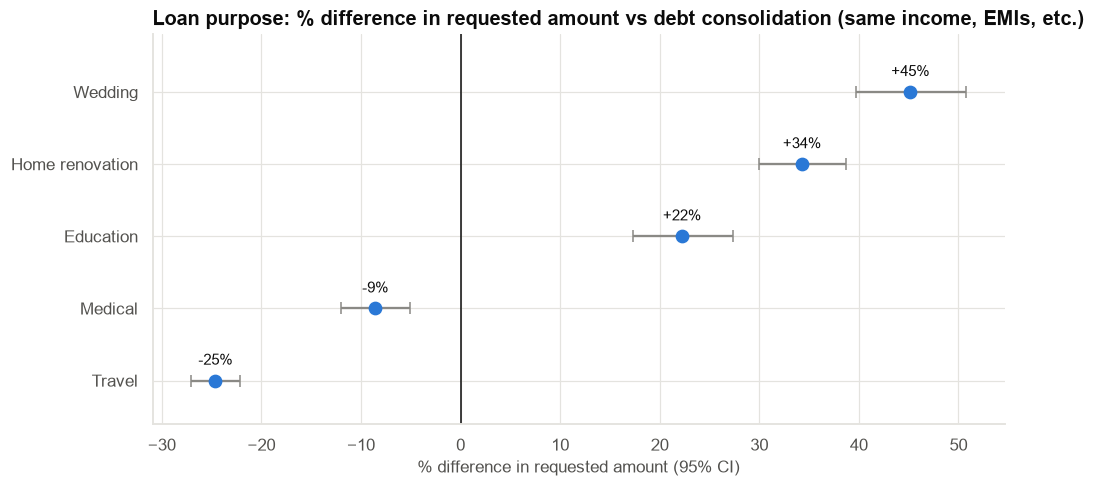

In [14]:
purpose = coef.loc[[i for i in coef.index if i.startswith("loan_purpose")]].copy()
purpose.index = [i.split("T.")[1].rstrip("]") for i in purpose.index]
purpose = purpose.sort_values("% effect")
fig, ax = plt.subplots(figsize=(10, 4.6))
y_ = np.arange(len(purpose))
ax.errorbar(purpose["% effect"], y_, xerr=[purpose["% effect"] - purpose["ci_low"].map(pct), purpose["ci_high"].map(pct) - purpose["% effect"]],
            fmt="o", color=PRIMARY, ecolor=INK_MUTED, capsize=4, ms=8)
ax.axvline(0, color=INK, lw=1)
for yi, v in zip(y_, purpose["% effect"]):
    ax.text(v, yi + 0.22, f"{v:+.0f}%", ha="center", fontsize=10)
ax.set_yticks(y_, purpose.index)
ax.set_ylim(-0.6, len(purpose) - 0.2)
ax.set(title="Loan purpose: % difference in requested amount vs debt consolidation (same income, EMIs, etc.)",
       xlabel="% difference in requested amount (95% CI)")
save_fig(fig, "fig04_purpose_effects", PATHS["figures"])
plt.show()

**How to say each coefficient in business language** (holding the other variables in the model fixed):

- **Income:** for salaried customers, 10% higher income goes with about +9% in the requested amount. For self-employed
  customers, about +10–11%.
- **Existing EMI:** each extra ₹1,000 of monthly EMI goes with a request about 1.2% smaller.
- **Purpose (vs debt consolidation):** weddings about +45%, home renovation about +34%, education about +22%, medical about
  −9%, travel about −25%.
- **Employment (at ₹50k income):** see the employment rows above. Professionals and self-employed customers request more
  than salaried customers with the same income, and the gap widens with income (interaction).
- **Credit score:** each +50 points goes with a request about +5% larger (a small effect).
- **Age, city tier:** no detectable association once income is accounted for.

### 12.1 Standardised coefficients (comparing numeric predictors on a common scale)

In [15]:
z = train.copy()
for c in ["log_income", "existing_emi_k", "age", "credit_score"]:
    z[c] = (z[c] - z[c].mean()) / z[c].std()
z["log_amount"] = (z["log_amount"] - z["log_amount"].mean()) / z["log_amount"].std()
m_std = smf.ols("log_amount ~ log_income + existing_emi_k + age + credit_score + employment_type + loan_purpose + city_tier", z).fit()
std_beta = m_std.params[["log_income", "existing_emi_k", "credit_score", "age"]].rename("standardised β (SD change in log amount per 1-SD change in X)")
save_table(std_beta.to_frame(), "standardised_coefficients", PATHS["tables"])
std_beta.to_frame()

,standardised β (SD change in log amount per 1-SD change in X)
log_income,0.7714
existing_emi_k,-0.2631
credit_score,0.0829
age,-0.0101


Standardising puts numeric predictors on a common "per standard deviation" scale. Income's effect dwarfs the others.
Caveats: standardised coefficients depend on how spread out each variable is **in this sample**. They don't apply to
dummy variables in a meaningful way, and they say nothing about which variable is easier or cheaper to change.

## Section 13 — Diagnostics and multicollinearity check

,VIF
log_income,1.6906
city_tier_Tier-2,1.3934
city_tier_Tier-3,1.3605
city_tier_Tier-1,1.3540
existing_emi_k,1.3294
loan_purpose_Home renovation,1.3249


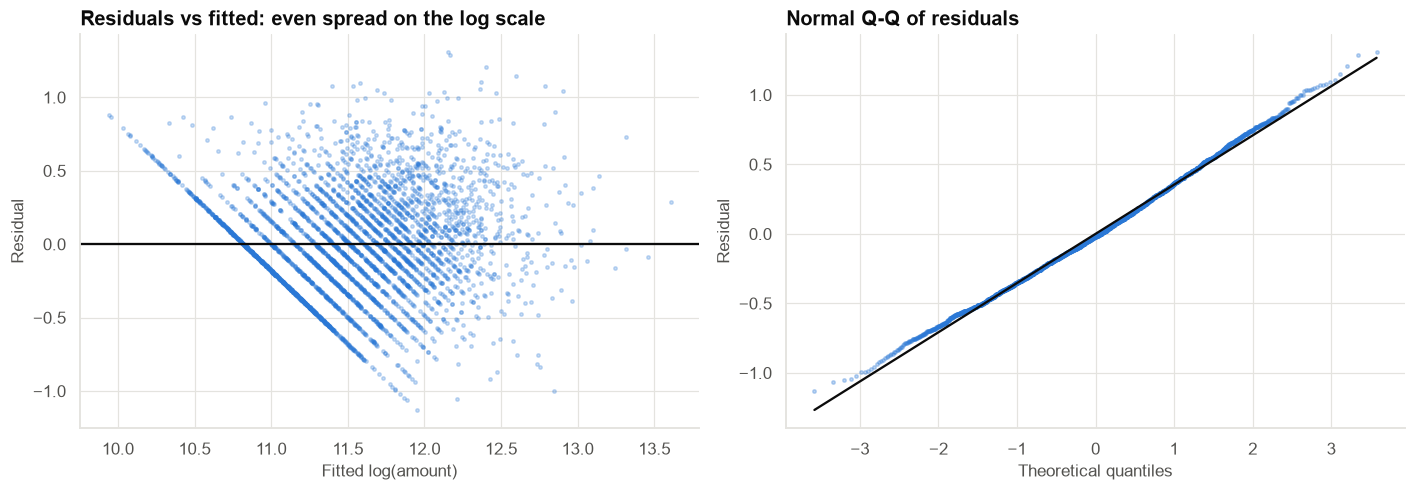

In [16]:
X = pd.get_dummies(train[["log_income", "existing_emi_k", "age", "credit_score", "employment_type", "loan_purpose", "city_tier"]],
                   drop_first=True, dtype=float)
Xc = sm.add_constant(X)
vif = pd.Series({c: variance_inflation_factor(Xc.values, i) for i, c in enumerate(Xc.columns) if c != "const"}, name="VIF").sort_values(ascending=False)
display(vif.head(6).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].scatter(final.fittedvalues, final.resid, s=5, alpha=0.25, color=PRIMARY); axes[0].axhline(0, color=INK)
axes[0].set(title="Residuals vs fitted: even spread on the log scale", xlabel="Fitted log(amount)", ylabel="Residual")
(osm, osr), (sl, ic, _) = stats.probplot(final.resid, dist="norm")
axes[1].scatter(osm, osr, s=5, alpha=0.3, color=PRIMARY); axes[1].plot(osm, sl * osm + ic, color=INK)
axes[1].set(title="Normal Q-Q of residuals", xlabel="Theoretical quantiles", ylabel="Residual")
fig.tight_layout()
save_fig(fig, "fig05_diagnostics", PATHS["figures"])
plt.show()

VIFs are low (max ≈ 1.7): predictors overlap (income relates to EMIs, score and tier) but not enough to destabilise the
coefficients. Residuals are evenly spread with near-normal tails (slightly flattened by the ₹50k floor and rounding).
The model's assumptions are reasonable.

## Section 14 — Prediction quality on the holdout

In [17]:
def pi_coverage(model, data, level=0.80):
    fr = model.get_prediction(data).summary_frame(alpha=1 - level)
    inside = (data["log_amount"] >= fr["obs_ci_lower"]) & (data["log_amount"] <= fr["obs_ci_upper"])
    width = np.exp(fr["obs_ci_upper"]) / np.exp(fr["obs_ci_lower"])
    return inside.mean(), np.median(width)

pred_rows = []
for name in ["M1: income only", "M4: + age, score, city tier (full)", "M5: + income × employment"]:
    m = models[name]
    pred = m.predict(test)
    r2_oos = 1 - ((test["log_amount"] - pred) ** 2).sum() / ((test["log_amount"] - test["log_amount"].mean()) ** 2).sum()
    cov_, width = pi_coverage(m, test)
    mape = np.median(np.abs(np.exp(pred) - test["requested_amount"]) / test["requested_amount"])
    pred_rows.append({"model": name, "holdout R² (log)": r2_oos, "80% PI coverage": cov_, "80% PI width (high ÷ low)": width,
                      "median abs % error": mape})
pred_q = pd.DataFrame(pred_rows).set_index("model")
save_table(pred_q, "holdout_prediction_quality", PATHS["tables"])
pred_q

,holdout R² (log),80% PI coverage,80% PI width (high ÷ low),median abs % error
model,,,,
M1: income only,0.4689,0.8050,3.1588,0.3054
"M4: + age, score, city tier (full)",0.6817,0.8210,2.5020,0.2270
M5: + income × employment,0.6856,0.8150,2.4898,0.2275


Adding the other drivers raises holdout R² from about 0.47 to about 0.69, and narrows the 80% prediction range from a
factor of roughly ×3.2 (high ÷ low) to about ×2.5, about 20% narrower, while keeping close to 80% coverage. The median
prediction error falls from about 31% to about 23%. **Finance's forecast and the offer
tiers both become materially sharper** than with income alone.

### 14.1 Three customer profiles

In [18]:
profiles = pd.DataFrame([
    {"profile": "Salaried, ₹60k income, ₹5k EMI, debt consolidation", "log_income": np.log(60_000 / 50_000), "employment_type": "Salaried",
     "existing_emi_k": 5, "loan_purpose": "Debt consolidation", "age": 34, "credit_score": 730, "city_tier": "Tier-1"},
    {"profile": "Self-employed, ₹60k income, ₹5k EMI, wedding", "log_income": np.log(60_000 / 50_000), "employment_type": "Self-employed",
     "existing_emi_k": 5, "loan_purpose": "Wedding", "age": 34, "credit_score": 730, "city_tier": "Tier-1"},
    {"profile": "Salaried, ₹60k income, ₹20k EMI, travel", "log_income": np.log(60_000 / 50_000), "employment_type": "Salaried",
     "existing_emi_k": 20, "loan_purpose": "Travel", "age": 34, "credit_score": 730, "city_tier": "Tier-1"},
])
for c in ["employment_type", "loan_purpose", "city_tier"]:
    profiles[c] = pd.Categorical(profiles[c], categories=train[c].cat.categories)
fr = final.get_prediction(profiles).summary_frame(alpha=0.20)
prof_out = pd.DataFrame({"typical request": [fmt_money(round(v, -4)) for v in np.exp(fr["mean"])],
                         "80% range": [f"{fmt_money(round(np.exp(a), -4))} – {fmt_money(round(np.exp(b), -4))}"
                                       for a, b in zip(fr["obs_ci_lower"], fr["obs_ci_upper"])]}, index=profiles["profile"])
save_table(prof_out, "profile_predictions", PATHS["tables"])
prof_out

,typical request,80% range
profile,,
"Salaried, ₹60k income, ₹5k EMI, debt consolidation","₹110,000","₹70,000 – ₹170,000"
"Self-employed, ₹60k income, ₹5k EMI, wedding","₹180,000","₹110,000 – ₹280,000"
"Salaried, ₹60k income, ₹20k EMI, travel","₹70,000","₹40,000 – ₹110,000"


Three customers with **the same income** have typical requests that differ by a factor of about 2.5, driven by purpose,
existing debt and employment. An income-only rule would offer all three the same amount.

## Section 15 — Results

In [19]:
results = pd.DataFrame([
    ["Income elasticity (salaried), full model", slope_tbl.loc["Salaried", "income elasticity"], slope_tbl.loc["Salaried", "ci_low"], slope_tbl.loc["Salaried", "ci_high"]],
    ["Income elasticity (self-employed)", slope_tbl.loc["Self-employed", "income elasticity"], slope_tbl.loc["Self-employed", "ci_low"], slope_tbl.loc["Self-employed", "ci_high"]],
    ["Income elasticity, income-only model", simple.loc["log_income", "coef"], simple.loc["log_income", "ci_low"], simple.loc["log_income", "ci_high"]],
    ["Existing EMI % per ₹1k: individual", pct(simple.loc["existing_emi_k", "coef"]), pct(simple.loc["existing_emi_k", "ci_low"]), pct(simple.loc["existing_emi_k", "ci_high"])],
    ["Existing EMI % per ₹1k: conditional", pct(final.params["existing_emi_k"]), pct(final.conf_int().loc["existing_emi_k", 0]), pct(final.conf_int().loc["existing_emi_k", 1])],
    ["City tier block F-test p", ftests.loc["city tier (3 dummies)", "p_value"], np.nan, np.nan],
    ["Age F-test p", ftests.loc["age", "p_value"], np.nan, np.nan],
    ["Income × employment interaction p", f_int["p_value"], np.nan, np.nan],
    ["Holdout R² (log): income only → final", pred_q.iloc[0]["holdout R² (log)"], pred_q.iloc[2]["holdout R² (log)"], np.nan],
    ["80% PI width (×): income only → final", pred_q.iloc[0]["80% PI width (high ÷ low)"], pred_q.iloc[2]["80% PI width (high ÷ low)"], np.nan],
], columns=["quantity", "estimate / value 1", "ci_low / value 2", "ci_high"]).set_index("quantity")
save_table(results, "key_results", PATHS["tables"])
results

,estimate / value 1,ci_low / value 2,ci_high
quantity,,,
"Income elasticity (salaried), full model",0.8670,0.8340,0.8999
Income elasticity (self-employed),1.0310,0.9851,1.0769
"Income elasticity, income-only model",0.8081,0.7806,0.8356
Existing EMI % per ₹1k: individual,0.5995,0.4548,0.7443
Existing EMI % per ₹1k: conditional,-1.2295,-1.3261,-1.1328
City tier block F-test p,0.3402,NaN,NaN
Age F-test p,0.3114,NaN,NaN
Income × employment interaction p,0.0000,NaN,NaN
Holdout R² (log): income only → final,0.4689,0.6856,NaN


## Section 16 — Interpretation

**Income is the main driver, and its effect was understated when studied alone.** Holding existing EMIs, purpose,
employment and other factors fixed, a 10% higher income goes with about a 9% larger request for salaried customers and
a larger response for the self-employed (interaction p < 0.001). The income-only elasticity (≈ 0.81) was biased
downward because it ignored existing EMIs.

**Three dashboard beliefs do not survive adjustment.**
- *Metro customers ask for more*: they earn more. Holding income fixed, city tier adds nothing (F-test p ≫ 0.05).
- *Older customers ask for more*: same story (age p ≫ 0.05 once income is included).
- *Indebted customers are credit-hungry*: backwards. Holding income fixed, each extra ₹1,000 of existing EMI goes with
  a request about 1.2% **smaller**. The positive individual association came from income.

**Credit score** has a small genuine association (≈ +5% per 50 points). **Loan purpose** matters a lot: weddings
about +45%, travel about −25% versus debt consolidation, at the same income.

**Prediction.** The full model explains about two-thirds of the variation in requested amounts on new applications
(holdout R² ≈ 0.69 vs ≈ 0.47 for income alone), with honest 80% ranges that are about 20% narrower.

**Language.** These are **conditional associations**: "among customers with the same income, EMIs, etc., those
with X request Y% more". They describe current customers, not what would happen if a customer's EMIs changed.

## Section 17 — What can we say?

### ✅ We can confidently say
- Income is the dominant driver of requested amounts. Purpose and existing EMIs are the next most important.
- City tier and age are **not** associated with requests once income is known.
- At the same income, customers with more existing EMIs request **less**.
- The income effect is stronger for self-employed customers.

### 📊 We have evidence that
- Credit score has a small positive association.
- A multi-driver model gives materially better forecasts and ranges than income alone.

### ❌ We cannot conclude
- That changing a customer's EMIs or score would change their request (causal claims).
- Anything about unobserved drivers (household size, assets, existing savings).
- That these patterns hold for approved amounts (this is demand, before credit decisions).

### 🔍 We would need additional analysis or data to conclude
- Approved vs requested amounts, to separate demand from policy (combine with Case 06).
- Additional application fields (dependants, housing) to narrow the ranges further.
- Experiments (e.g., offer framing) for causal questions.

## Section 18 — Business interpretation

| Statistical finding | Data scientist interpretation | Business interpretation | Business action |
|---|---|---|---|
| Elasticity ≈ 0.9 (salaried), higher for self-employed | Income dominant; interaction | Offers should scale with income, more steeply for self-employed | Income-based tiers with a self-employed adjustment |
| Existing EMI −1.2% per ₹1k (conditional) vs + (individual) | Sign flip; affordability | Indebted customers want less, not more | Drop "credit-hungry" targeting; use EMI headroom in offers |
| City tier, age: n.s. after income | Proxies | Geography/age-based offer tiers add nothing beyond income | Remove city tier and age from offer design |
| Purpose: wedding +45% … travel −25% | Large, stable effects | Purpose is a strong, cheap signal | Purpose-specific default offer amounts |
| Holdout R² 0.47 → 0.69; ranges ~20% narrower | Better prediction | Sharper disbursement forecasts | Give Finance the multi-driver model |
| Tenure raises R² but is chosen with the amount | Bad control | Must not be used as a driver | Keep tenure out of driver and pre-offer models |

## Section 19 — Limitations

- **Observational, cross-sectional data:** conditional associations, not causal effects.
- **Omitted variables:** "holding constant" only covers variables in the model.
- **Requested amounts only:** say nothing about what is approved or repaid.
- **Log model:** predictions are medians. Use the smearing factor for totals (Case 06).
- **Synthetic data.**

## Section 20 — Final recommendation

1. **Redesign offer tiers around income, existing-EMI headroom, purpose and employment type.** Drop city tier and age as
   tiering variables.
2. **Retire the "credit-hungry" targeting rule.** At the same income, indebted customers want smaller loans.
3. **Give Finance the multi-driver model** for disbursement forecasting (holdout R² ≈ 0.69, calibrated 80% ranges).
4. **Keep requested tenure out** of driver and pre-offer models.

## Section 21 — What would I do next?

- Model **approved** amounts and the gap between requested and approved (policy effect).
- Investigate the confounding and suppression patterns more formally (Case 08) and check multicollinearity risks when
  adding correlated bureau variables (Case 09).
- Validate the model on next quarter's applications (drift monitoring).

---

### Concepts covered
Multiple regression · individual vs conditional relationships · holding other variables constant · omitted-variable
bias · proxies and confounding · sign flips · added-variable plots · dummy variables and reference categories ·
categorical × numeric interactions · interpreting main effects with interactions · nested F-tests · partial R² ·
standardised coefficients · adjusted R² · VIF · log-scale % effects · bad controls (variables determined with the
outcome) · holdout validation of predictions and intervals.

### Exercises
1. Change the reference category of `loan_purpose` to "Travel". Which coefficients change, and which predictions change?
2. Centre log income at log(₹50,000) and refit M5. Interpret the employment dummies now.
3. Add `existing_emi_k × employment_type`. Is there evidence that the EMI effect differs by job type?
4. Fit the model on the raw (unlogged) amount and compare holdout PI coverage by income band (as in Case 06).